<a href="https://colab.research.google.com/github/Sadanadanapala/Simple--Chatbot/blob/main/CARDIOVASCULAR%20%20DISEASE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
#Import Libraries and Load Datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Load the dataset (replace 'heart.csv' with your actual dataset filename)
df = pd.read_csv('/content/heart.csv')
print(df.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  


In [9]:
# Print all column names to see what the target column is called
print(df.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [10]:
# Data Pre-Processing Operations
# Check for missing values
print("Missing values in each column:\n", df.isnull().sum())

# Check for duplicate rows and drop them if any
df.drop_duplicates(inplace=True)

# Separate features (X) and target (y)
# Note: Change 'target' to the actual name of your target column if it differs (e.g., 'output', 'condition')
X = df.drop(columns=['target'])
y = df['target']

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Missing values in each column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


/tmp/ipykernel_641/1609566488.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2')


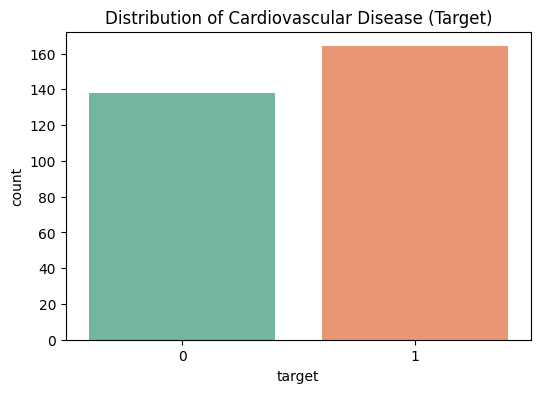

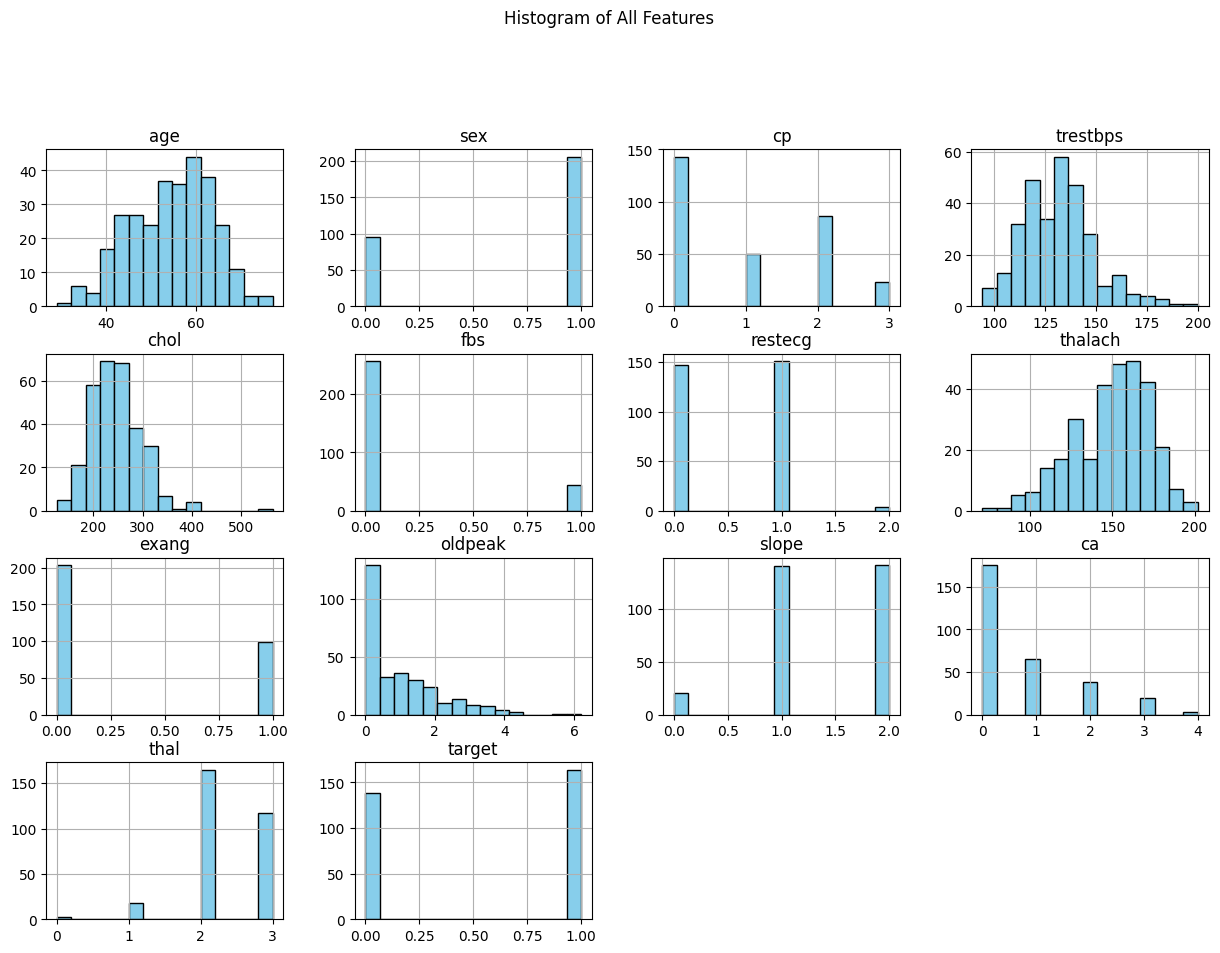

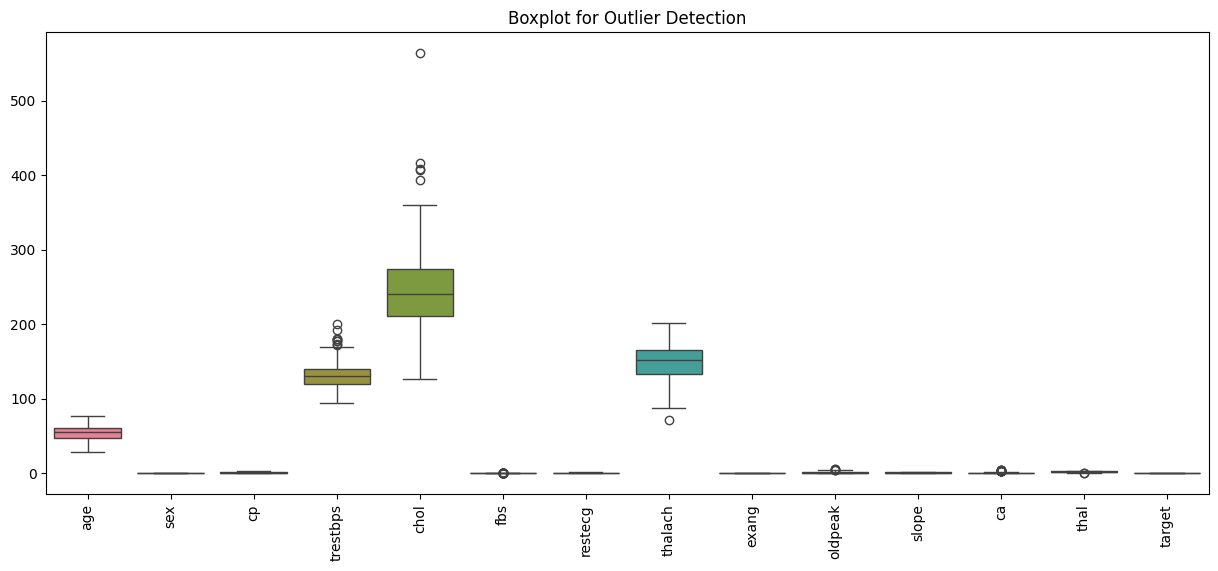

In [11]:
#Data Analysis and Visualization
# 1. Target Variable Distribution Countplot
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='Set2')
plt.title('Distribution of Cardiovascular Disease (Target)')
plt.show()

# 2. Histograms for numerical features
df.hist(bins=15, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle('Histogram of All Features', y=1.02)
plt.show()

# 3. Boxplot to check for outliers
plt.figure(figsize=(15, 6))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.title('Boxplot for Outlier Detection')
plt.show()

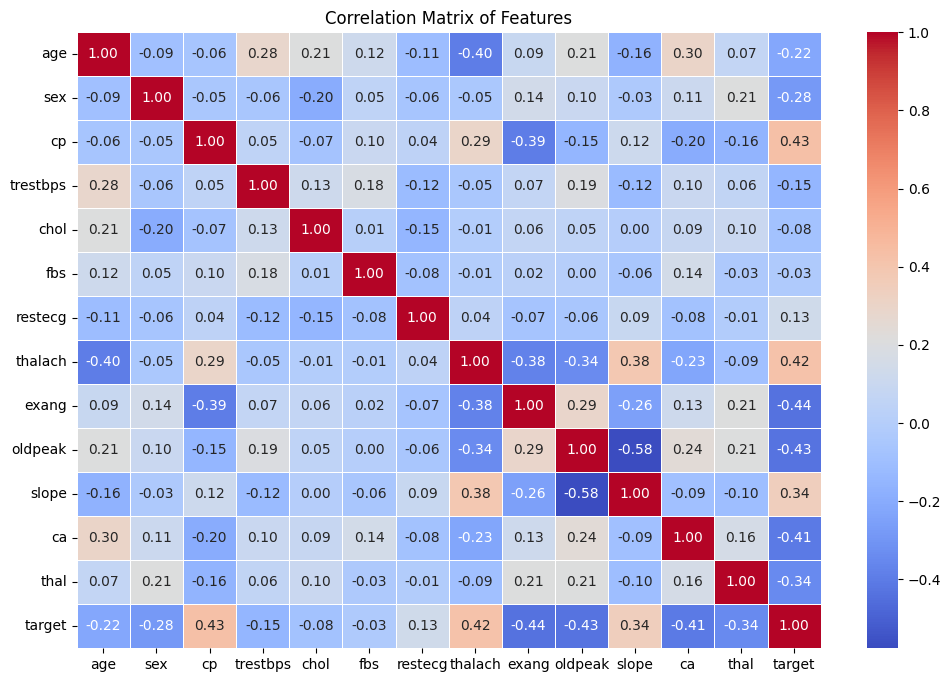

In [12]:
#Correlation Matrix
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Features')
plt.show()


In [13]:
#Machine Learning Techniques
# Initialize models dictionary
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Machine": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

accuracy_results = {}

# Train and evaluate each model
for name, model in models.items():
    # Use scaled data for distance-based/linear models, unscaled or scaled works for trees/forests
    if name in ["Logistic Regression", "K-Nearest Neighbors", "Support Vector Machine"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    accuracy_results[name] = acc
    print(f"--- {name} ---")
    print(f"Accuracy: {acc * 100:.2f}%")
    print(confusion_matrix(y_test, y_pred))
    print("\n")

# Summary of Accuracies
accuracy_df = pd.DataFrame(list(accuracy_results.items()), columns=['Model', 'Accuracy']).sort_values(by='Accuracy', ascending=False)
print("Model Accuracy Comparison:")
print(accuracy_df)

--- Logistic Regression ---
Accuracy: 81.97%
[[24  5]
 [ 6 26]]


--- K-Nearest Neighbors ---
Accuracy: 91.80%
[[28  1]
 [ 4 28]]


--- Support Vector Machine ---
Accuracy: 86.89%
[[27  2]
 [ 6 26]]


--- Decision Tree ---
Accuracy: 77.05%
[[25  4]
 [10 22]]


--- Random Forest ---
Accuracy: 86.89%
[[26  3]
 [ 5 27]]


Model Accuracy Comparison:
                    Model  Accuracy
1     K-Nearest Neighbors  0.918033
4           Random Forest  0.868852
2  Support Vector Machine  0.868852
0     Logistic Regression  0.819672
3           Decision Tree  0.770492


In [14]:
#Machine Learning Model
# Automatically select the model with the highest accuracy from our evaluation
best_model_name = accuracy_df.iloc[0]['Model']
print(f"The best performing model is: {best_model_name}")

# Retrain and finalize the best model (using Random Forest as an example below)
final_model = RandomForestClassifier(random_state=42)
final_model.fit(X_train, y_train)

# Final evaluation report
final_predictions = final_model.predict(X_test)
print("Classification Report for the Final Model:")
print(classification_report(y_test, final_predictions))

The best performing model is: K-Nearest Neighbors
Classification Report for the Final Model:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87        29
           1       0.90      0.84      0.87        32

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



In [15]:
pip install streamlit pandas numpy scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 36.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


2026-10-28 12:30:58.128 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 12:30:58.130 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 12:30:58.518 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-28 12:30:58.521 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 12:30:58.522 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 12:30:58.527 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 12:30:58.529 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

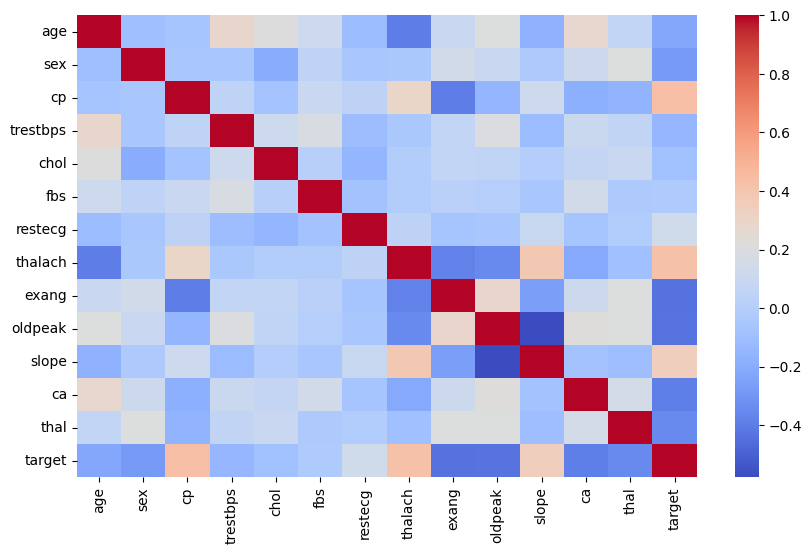

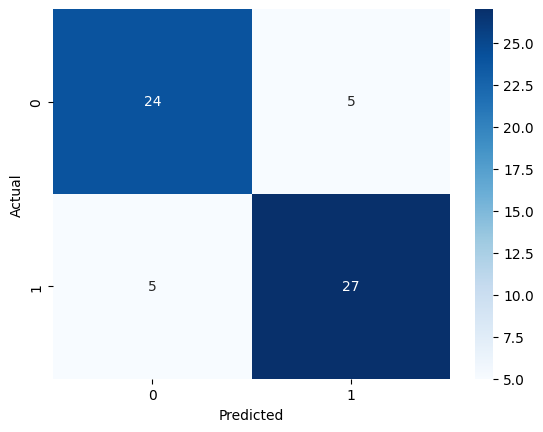

In [16]:
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Page Configuration
st.set_page_config(page_title="Cardiovascular Disease Prediction", layout="wide")

st.title("❤️ Cardiovascular Disease Prediction Dashboard")
st.write("An interactive web application for analyzing heart disease data and predicting patient risk.")

# Load Dataset (Make sure 'heart.csv' is in the same directory)
@st.cache_data
def load_data():
    # Replace 'heart.csv' with your actual dataset file name
    df = pd.read_csv('heart.csv')
    return df

df = load_data()

# Data Preprocessing & Model Training
target_col = 'target' # Change this if your target column has a different name (e.g., 'num', 'output')
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Navigation Tabs
tab1, tab2, tab3 = st.tabs(["📊 Data Exploration", "🤖 Model Performance", "🔍 Make Prediction"])

with tab1:
    st.header("Dataset Overview & Visualizations")
    st.write("Preview of the dataset:")
    st.dataframe(df.head())

    st.subheader("Correlation Matrix Heatmap")
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(df.corr(), annot=False, cmap='coolwarm', ax=ax)
    st.pyplot(fig)

with tab2:
    st.header("Machine Learning Model Evaluation")
    st.metric(label="Random Forest Accuracy", value=f"{accuracy * 100:.2f}%")

    st.subheader("Confusion Matrix")
    fig, ax = plt.subplots()
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    st.pyplot(fig)

with tab3:
    st.header("Patient Risk Predictor")
    st.write("Enter patient parameters in the sidebar/form to predict heart disease risk.")

    # Create input fields dynamically based on feature columns
    input_data = {}
    col1, col2, col3 = st.columns(3)

    for i, col in enumerate(X.columns):
        if i % 3 == 0:
            with col1:
                input_data[col] = st.number_input(f"{col}", float(df[col].min()), float(df[col].max()), float(df[col].mean()))
        elif i % 3 == 1:
            with col2:
                input_data[col] = st.number_input(f"{col}", float(df[col].min()), float(df[col].max()), float(df[col].mean()))
        else:
            with col3:
                input_data[col] = st.number_input(f"{col}", float(df[col].min()), float(df[col].max()), float(df[col].mean()))

    if st.button("Predict Risk"):
        input_df = pd.DataFrame([input_data])
        prediction = model.predict(input_df)
        prediction_proba = model.predict_proba(input_df)

        if prediction[0] == 1:
            st.error(f"⚠️ High Risk of Cardiovascular Disease detected! (Probability: {prediction_proba[0][1]*100:.2f}%)")
        else:
            st.success(f"✅ Low Risk of Cardiovascular Disease. (Probability: {prediction_proba[0][0]*100:.2f}%)")